# MERFISH Registration Comparison

Compare MLP, splat, PASTE, and CAST registration on two mouse-brain sections under
controlled rotation and translation. This notebook reads a completed-run snapshot:
**no model fitting, no tuning loops, and no execution of another notebook.**

One setting per method is chosen by its average coverage-weighted expression cosine
across the five development conditions, then used unchanged in every plot. These are
development results from one section pair, not independent biological validation.
Geometry warnings remain visible rather than excluding completed methods.
This report uses the corrected, support-regularized non-affine warp with convergence-checked inversion. The unperturbed condition retains the sections' existing alignment; it is not a same-section identity reconstruction.


In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

PROJECT_ROOT = Path.cwd().resolve()
while not ((PROJECT_ROOT / 'pyproject.toml').exists() and (PROJECT_ROOT / 'paper').is_dir()):
    if PROJECT_ROOT == PROJECT_ROOT.parent:
        raise RuntimeError('Could not locate the repository root')
    PROJECT_ROOT = PROJECT_ROOT.parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from paper.registration_comparison import load_comparison, summarize_comparison, plot_condition_scores
import importlib
import paper.registration_reporting as registration_reporting
overlay_figure = importlib.reload(registration_reporting).overlay_figure

RUN_ID = '2444120bc9d3aedaf0e9'
RUN_DIR = PROJECT_ROOT / 'notebooks/checkpoints/multislice_registration/fair_tuning/supported_invertible_v2/runs' / RUN_ID
FIGURE_DIR = PROJECT_ROOT / 'figures/merfish_registration_comparison' / RUN_ID
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

bundle = load_comparison(RUN_DIR / 'comparison_snapshot.npz')
comparison, selected_results, threshold_sensitivity = summarize_comparison(bundle)
conditions = list(bundle['inputs'])
plt.rcParams.update({'font.family': 'DejaVu Sans', 'font.size': 10, 'axes.titlesize': 11,
                     'axes.labelsize': 10, 'figure.dpi': 100, 'savefig.dpi': 180})
pd.options.display.float_format = lambda x: f'{x:.4g}'
print('Sections:', ' vs '.join(bundle['metadata']['sections']))
print('Registration measurements:', len(bundle['reference']), 'and', len(next(iter(bundle['inputs'].values()))))
print('Genes:', bundle['metadata']['gene_count'], '| Conditions:', len(conditions), '| Run:', RUN_ID)
assert bundle['metadata']['run_id'] == RUN_ID
assert bundle['metadata']['study'] == 'supported_invertible_v2'
METHOD_ORDER = ['Unregistered', 'MLP affine', 'Splat affine', 'Splat non-affine', 'PASTE', 'CAST affine', 'CAST non-affine']
condition_labels = {c: c.replace('identity', 'Unperturbed').replace('level1_', 'Moderate | ').replace('level2_', 'Strong | ') for c in conditions}


Sections: C57BL6J-638850.36 vs C57BL6J-638850.37
Registration measurements: 2400 and 2400
Genes: 550 | Conditions: 5 | Run: 2444120bc9d3aedaf0e9


## Experiment and Readout

Each method receives the same registration measurement subset and expression panel. MLP and splat methods align fitted expression fields; PASTE uses expression-informed optimal transport; CAST uses learned spatial-expression representations. Non-affine splat registration refines an affine fit with a smooth, constrained displacement field.

There are six candidate settings per family. One completed setting per method is selected by its mean development score, not separately for each condition. Equal candidate counts do not imply equal compute or exhaustive tuning. Coverage/folding warnings are reported rather than hidden.


In [2]:
case_table = pd.DataFrame(bundle['metadata']['cases'])
case_table['translation_magnitude'] = case_table['translation'].map(lambda x: float(np.linalg.norm(x)))
display(case_table[['name', 'angle_degrees', 'translation_magnitude']].rename(columns={
    'name': 'Condition', 'angle_degrees': 'Rotation (degrees)',
    'translation_magnitude': 'Translation (original normalized frame)'}))


,Condition,Rotation (degrees),Translation (original normalized frame)
0,identity,0,0
1,level1_seed2103,15,0.08
2,level1_seed2105,-15,0.08
3,level2_seed2103,35,0.15
4,level2_seed2105,-35,0.15


## Overall Comparison

Higher expression cosine and coverage are better; lower folding is better.
**Weighted cosine** counts unmatched measurements as zero, while **profile cosine**
only scores valid matched measurements. Neither is percentage anatomical accuracy.
The table averages the five conditions; folds are the worst observed fraction.

In [3]:
display(comparison.drop(columns='candidate').set_index('method').rename(columns={
    'candidate': 'Setting', 'weighted_cosine': 'Weighted cosine', 'profile_cosine': 'Profile cosine',
    'coverage': 'Mean coverage', 'worst_fold_fraction': 'Worst fold fraction',
    'geometry_warnings': 'Geometry warning'}))
comparison.to_csv(FIGURE_DIR / 'comparison.csv', index=False)

,Weighted cosine,Profile cosine,Mean coverage,Worst fold fraction,Geometry warning
method,,,,,
Splat affine,0.6178,0.6299,0.9808,0,none
Splat non-affine,0.6175,0.6317,0.9775,0.00105,none
CAST non-affine,0.6083,0.6292,0.9667,0.0042,none
PASTE,0.5841,0.5979,0.977,0,none
MLP affine,0.5675,0.5927,0.9574,0,none
CAST affine,0.5235,0.573,0.91,0,coverage
Unregistered,0.4624,0.5319,0.8628,0,not fitted


## Robustness to Misalignment

The same selected setting is used at every point. A decline with stronger perturbation
indicates sensitivity to starting alignment. Seeds change the imposed perturbation,
not the biological section pair; these are not independent biological replicates.

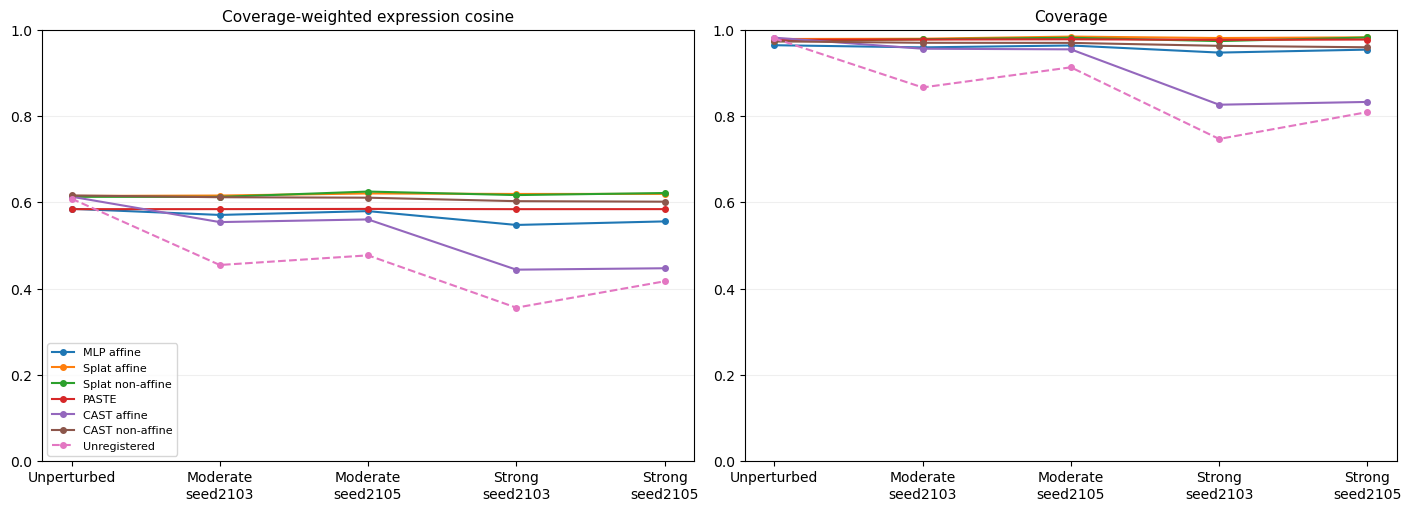

In [4]:
fig = plot_condition_scores(selected_results, conditions)
fig.savefig(FIGURE_DIR / 'performance_by_condition.png', bbox_inches='tight', facecolor='white')
plt.show()
plt.close(fig)

## Does Non-Affine Refinement Help?

Positive score differences favor non-affine registration. Coverage must be read alongside expression agreement: better similarity among the remaining matches can coexist with worse overall alignment. The two methods below use their respective globally selected settings, so this is a selected-method comparison, not a matched-hyperparameter ablation. Perturbation seeds are not biological replicates.


,Delta coverage weighted cosine,Delta profile cosine,Delta coverage
condition,,,
identity,-0.001993,0.001309,-0.005208
level1_seed2103,-0.003081,-0.002362,-0.00125
level1_seed2105,0.004389,0.006211,-0.002708
level2_seed2103,-0.002584,0.001942,-0.007083
level2_seed2105,0.001953,0.002276,-0.0004167


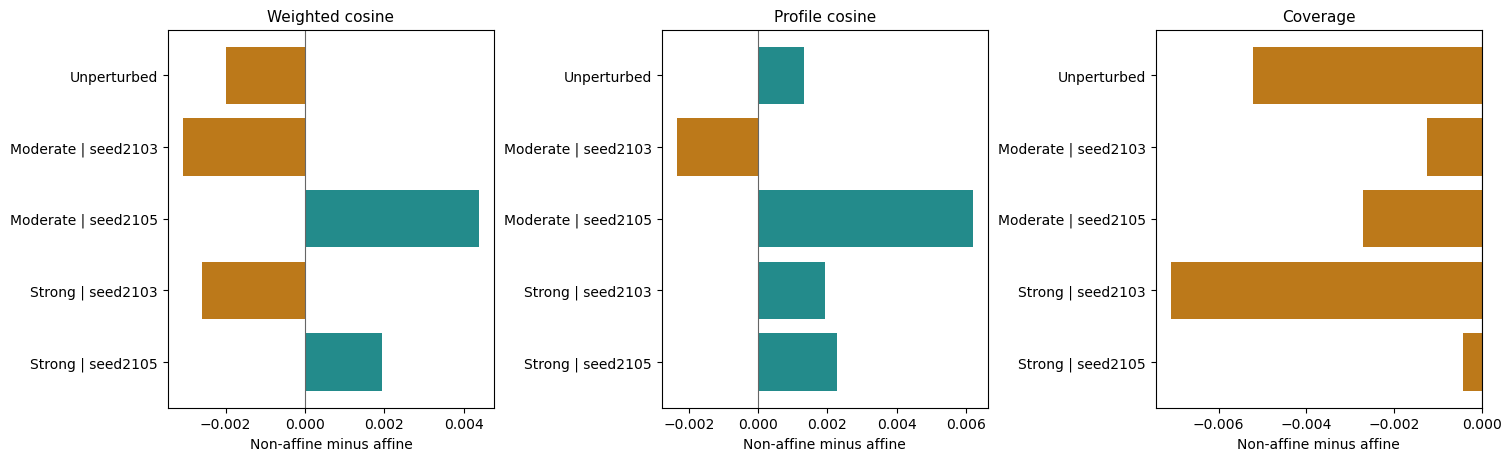

In [5]:
columns = ['coverage_weighted_cosine', 'profile_cosine', 'coverage']
affine = selected_results[selected_results.method == 'Splat affine'].set_index('condition').reindex(conditions)
nonaffine = selected_results[selected_results.method == 'Splat non-affine'].set_index('condition').reindex(conditions)
delta = nonaffine[columns] - affine[columns]
display(delta.rename(columns={c: 'Delta ' + c.replace('_', ' ') for c in columns}))
delta.to_csv(FIGURE_DIR / 'nonaffine_minus_affine.csv')
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), constrained_layout=True)
for ax, metric, title in zip(axes, columns, ['Weighted cosine', 'Profile cosine', 'Coverage']):
    values = delta[metric].to_numpy()
    ax.barh(range(len(conditions)), values, color=np.where(values >= 0, '#238b8b', '#bc791a'))
    ax.axvline(0, color='0.4', linewidth=0.8)
    ax.set(yticks=range(len(conditions)), yticklabels=[condition_labels[c] for c in conditions],
           title=title, xlabel='Non-affine minus affine')
    ax.invert_yaxis()
fig.savefig(FIGURE_DIR / 'nonaffine_refinement.png', bbox_inches='tight', facecolor='white')
plt.show()
plt.close(fig)


## Is the Warp Numerically Reliable?

Round-trip error checks whether mapping back and then forward recovers the original coordinate; it is not anatomical accuracy. The five-step error shows what truncating inversion would do on the **current** warp, not on the previous unconstrained fit. Support distance measures proximity to sampled reference measurements, not an exact tissue boundary. The soft margin is 0.02 in the padded normalized frame; some outside-margin measurements are expected between different sections.

Sampled triangle fold fractions can be nonzero even for an invertible continuous warp: connecting sparsely mapped vertices by straight edges is an approximation. Inspect this diagnostic together with inverse convergence and support, not as an exact damaged-area estimate.


In [6]:
diagnostics = pd.DataFrame(bundle['metadata']['inverse_diagnostics'])
chosen = int(comparison.set_index('method').loc['Splat non-affine', 'candidate'])
diagnostics = diagnostics[diagnostics.candidate == chosen].set_index('condition').reindex(conditions)
display(diagnostics[['roundtrip_max', 'five_step_roundtrip_max', 'unconverged_fraction',
                     'nearest_support_distance_q99', 'nearest_support_distance_max',
                     'outside_support_margin_fraction']])
diagnostics.to_csv(FIGURE_DIR / 'selected_warp_diagnostics.csv')
selected_results.to_csv(FIGURE_DIR / 'selected_results_by_condition.csv', index=False)


,roundtrip_max,five_step_roundtrip_max,unconverged_fraction,nearest_support_distance_q99,nearest_support_distance_max,outside_support_margin_fraction
condition,,,,,,
identity,3.817e-07,0.0007844,0,0.01934,0.03279,0.008333
level1_seed2103,4.215e-07,0.001853,0,0.01829,0.04261,0.005417
level1_seed2105,2.666e-07,0.0004584,0,0.0156,0.0238,0.0008333
level2_seed2103,2.149e-07,0.0002982,0,0.01599,0.03401,0.005
level2_seed2105,4.14e-07,0.0005075,0,0.01409,0.02084,0.0004167


## Alignment

Blue shows reference section A; orange shows section B before or after alignment.
All difficulty conditions are shown without fold-edge overlays. Numerical fold diagnostics
remain in the table and panel captions. All panels within a figure use the same coordinate limits.
This view includes every selected method, regardless of geometry warnings.

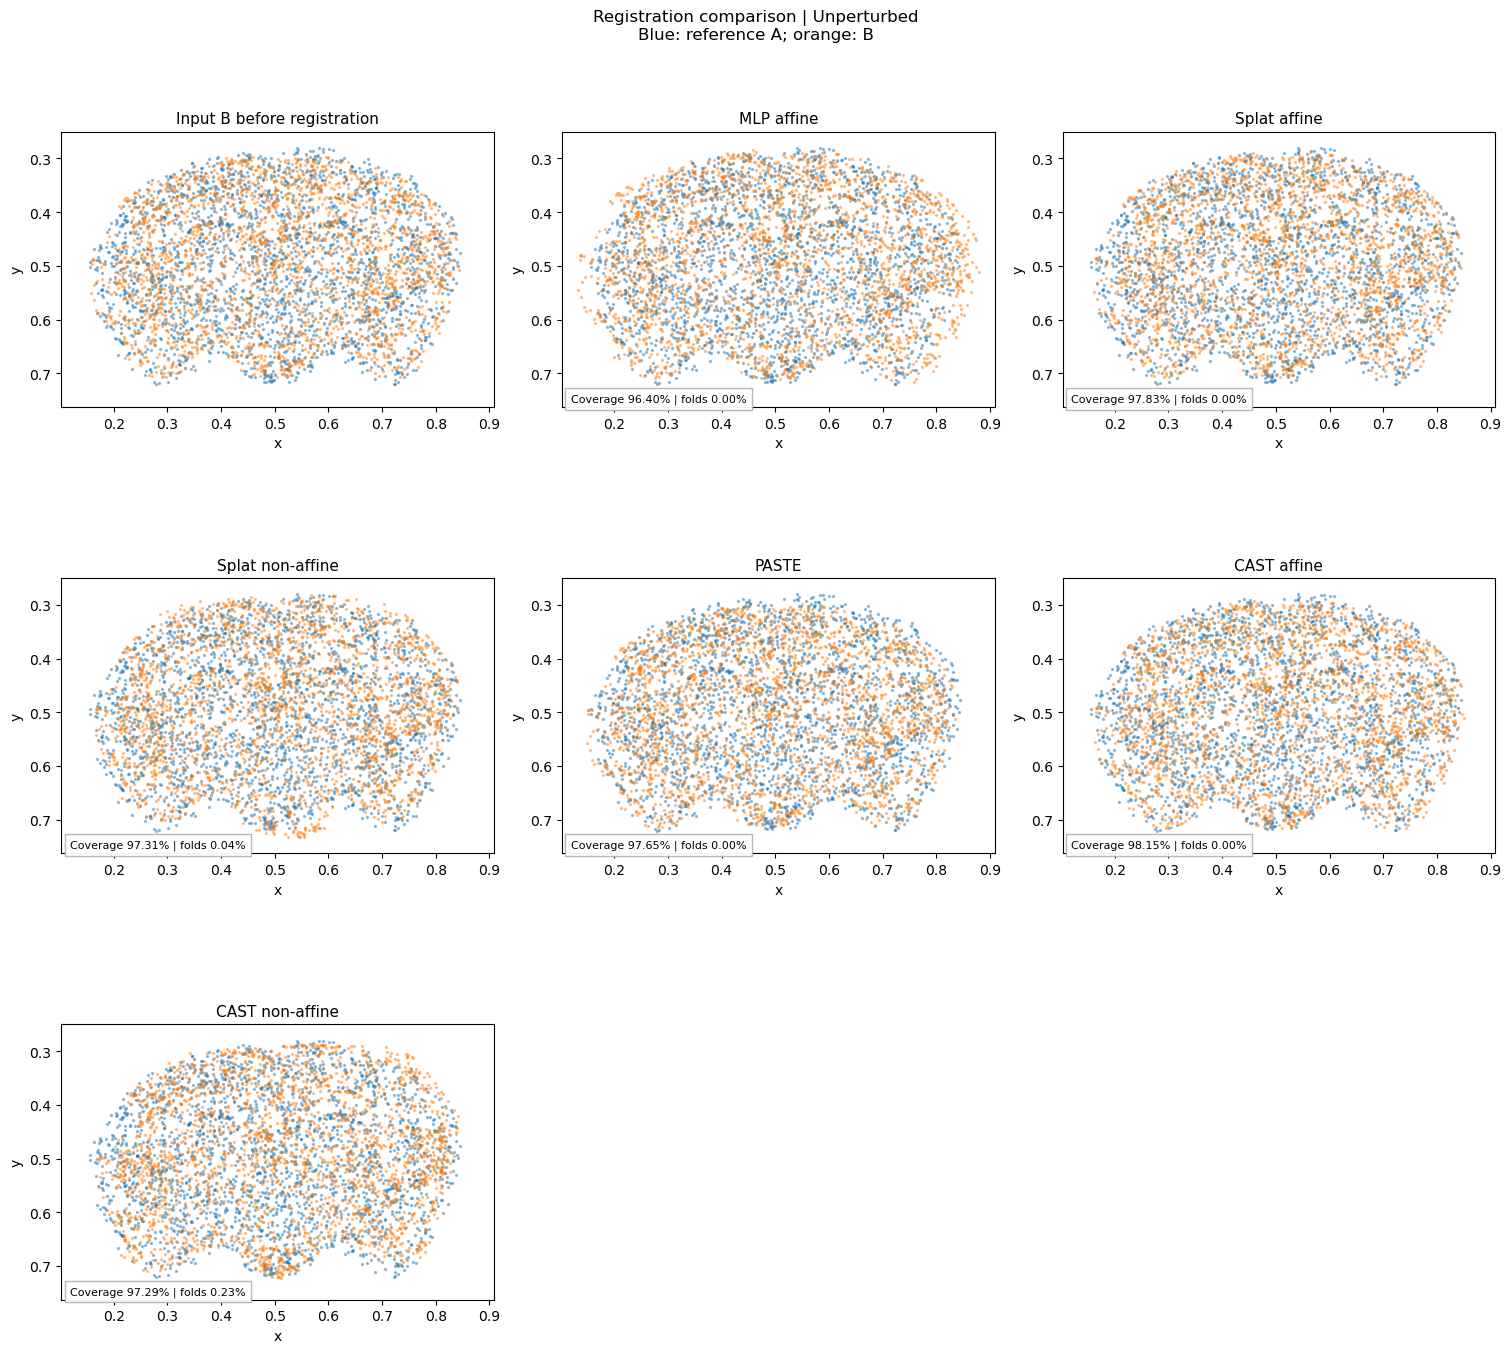

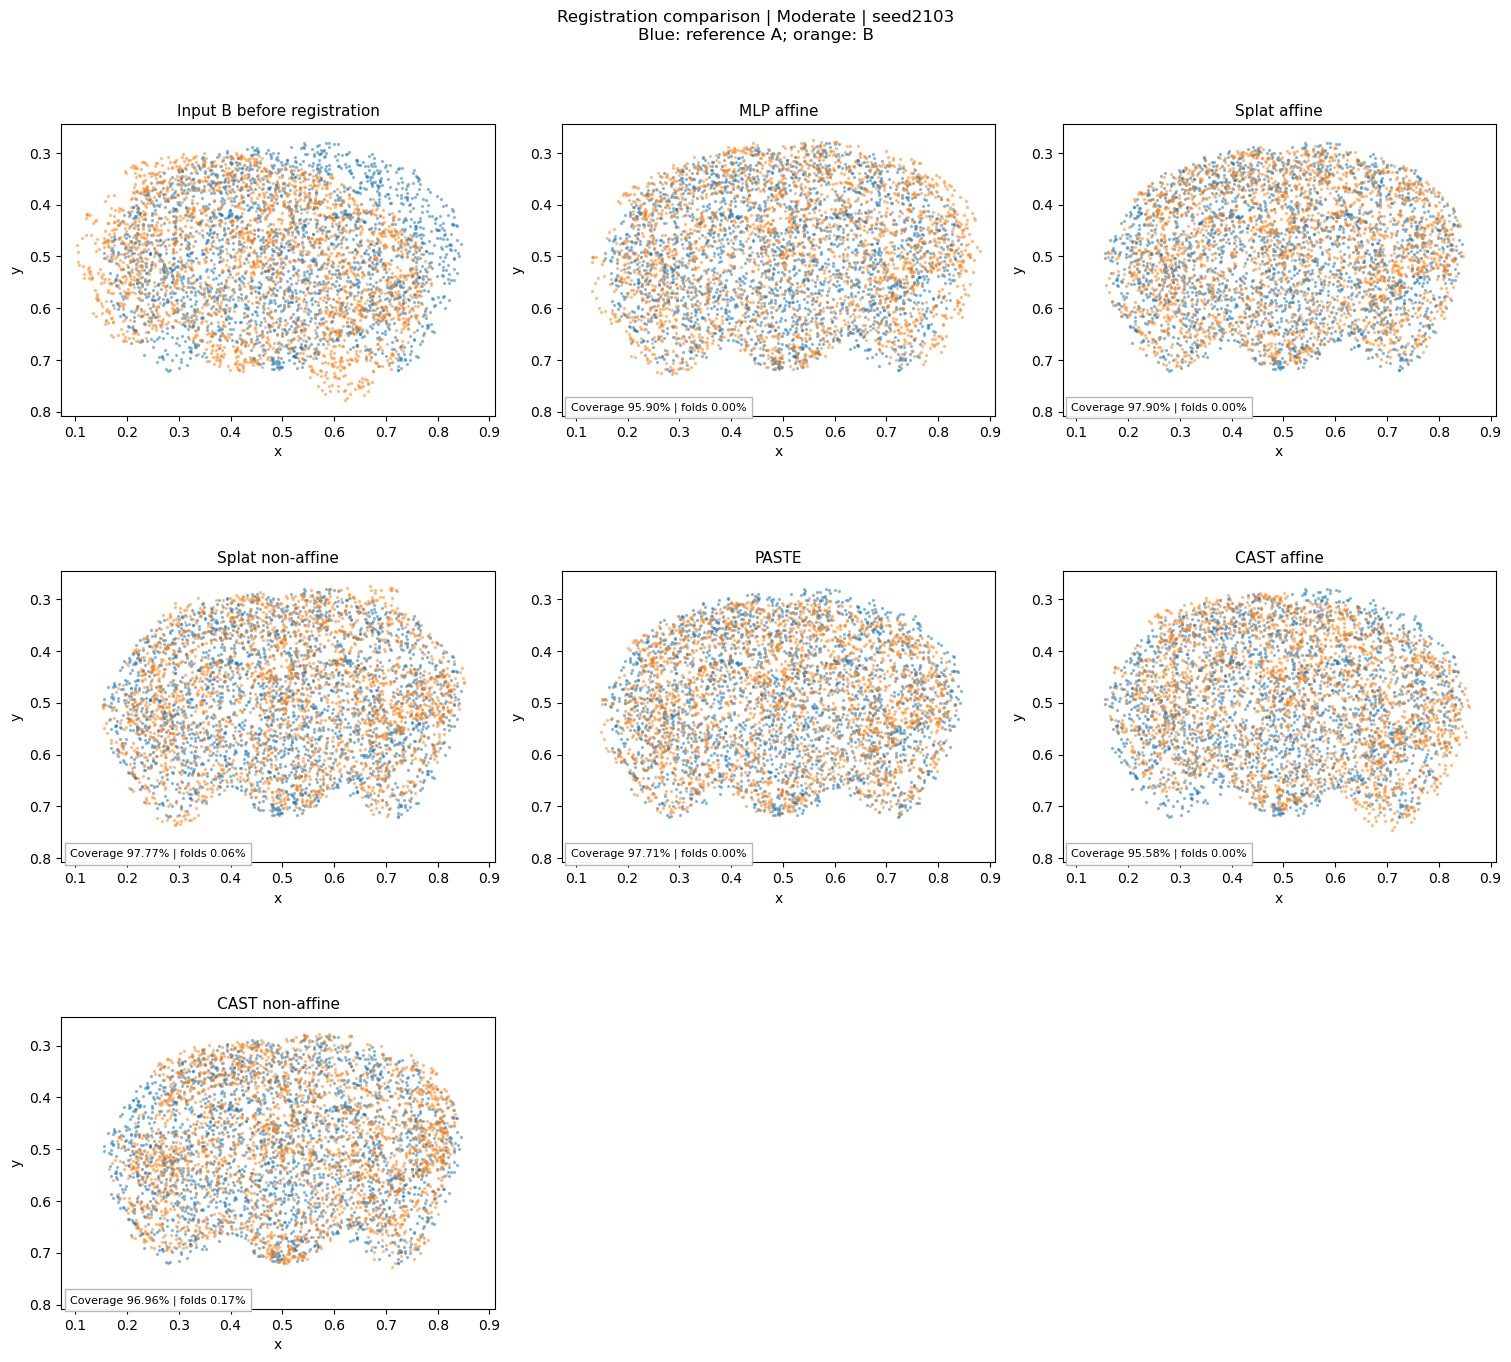

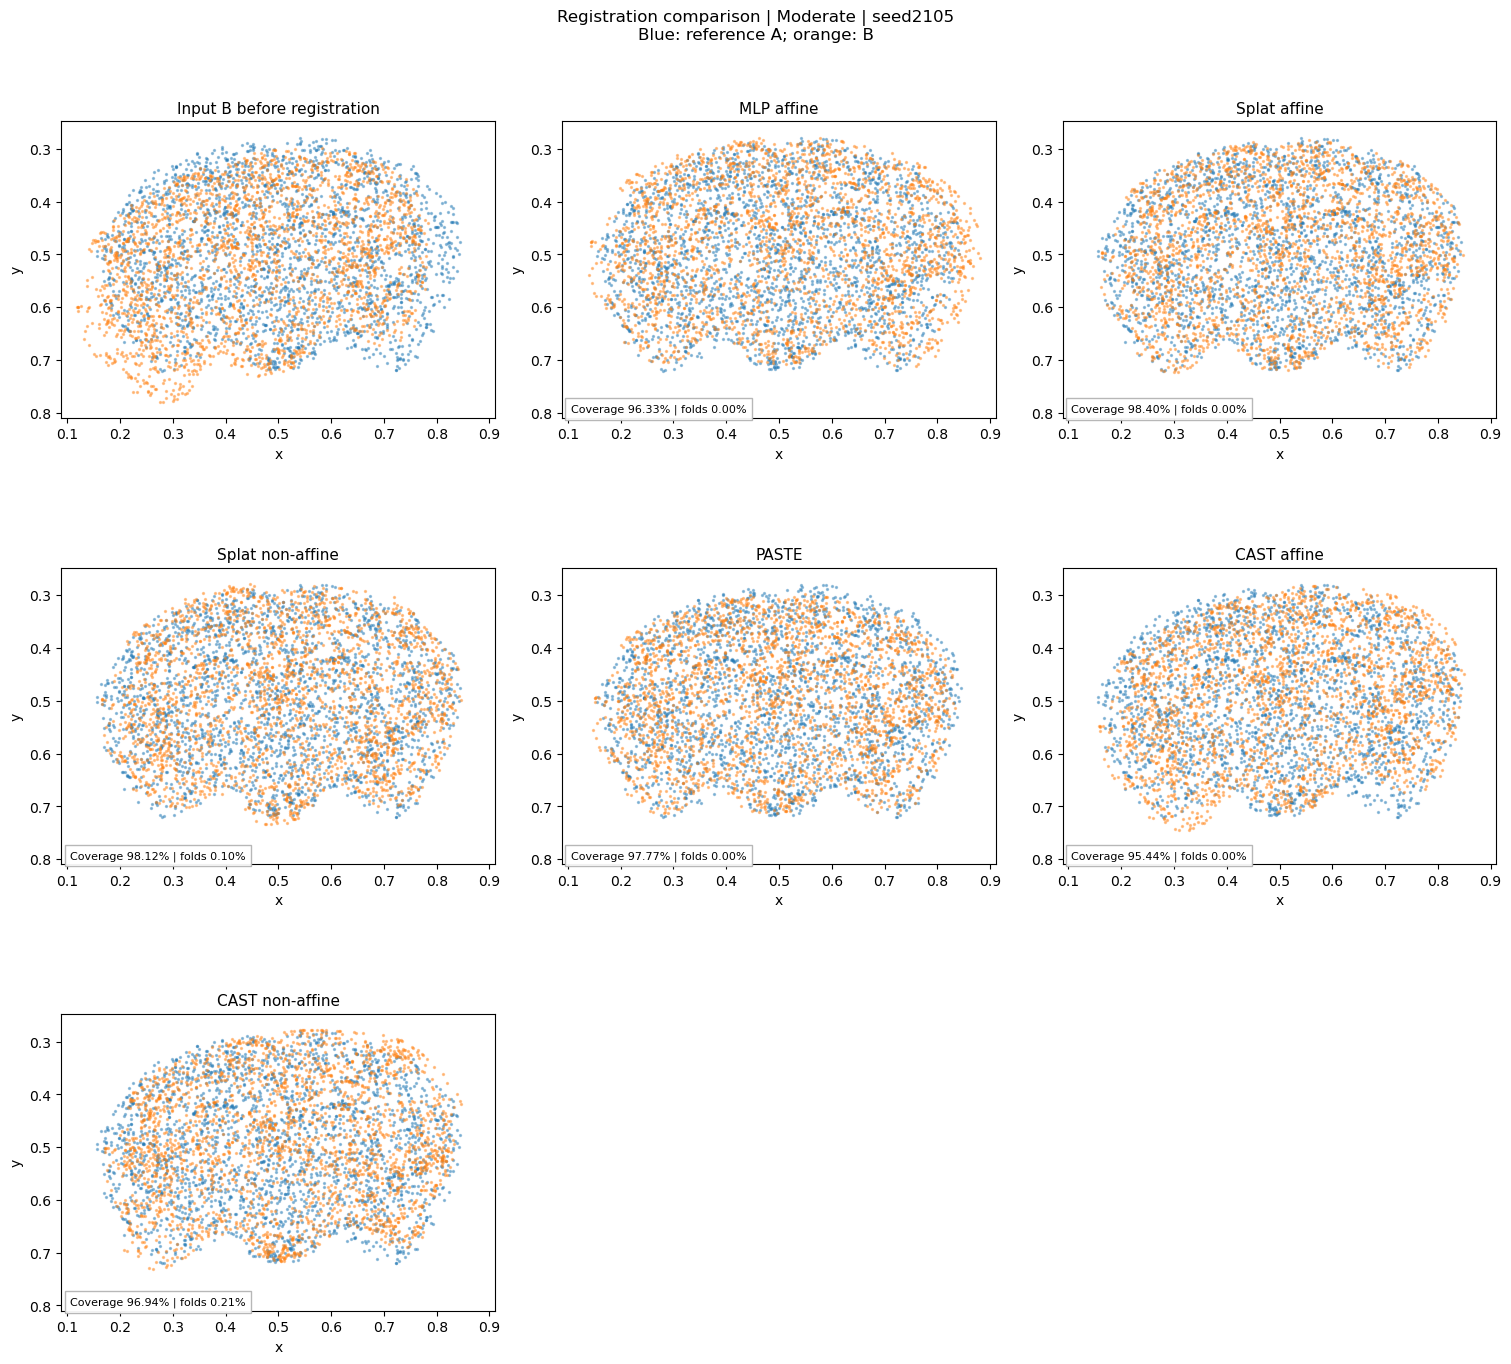

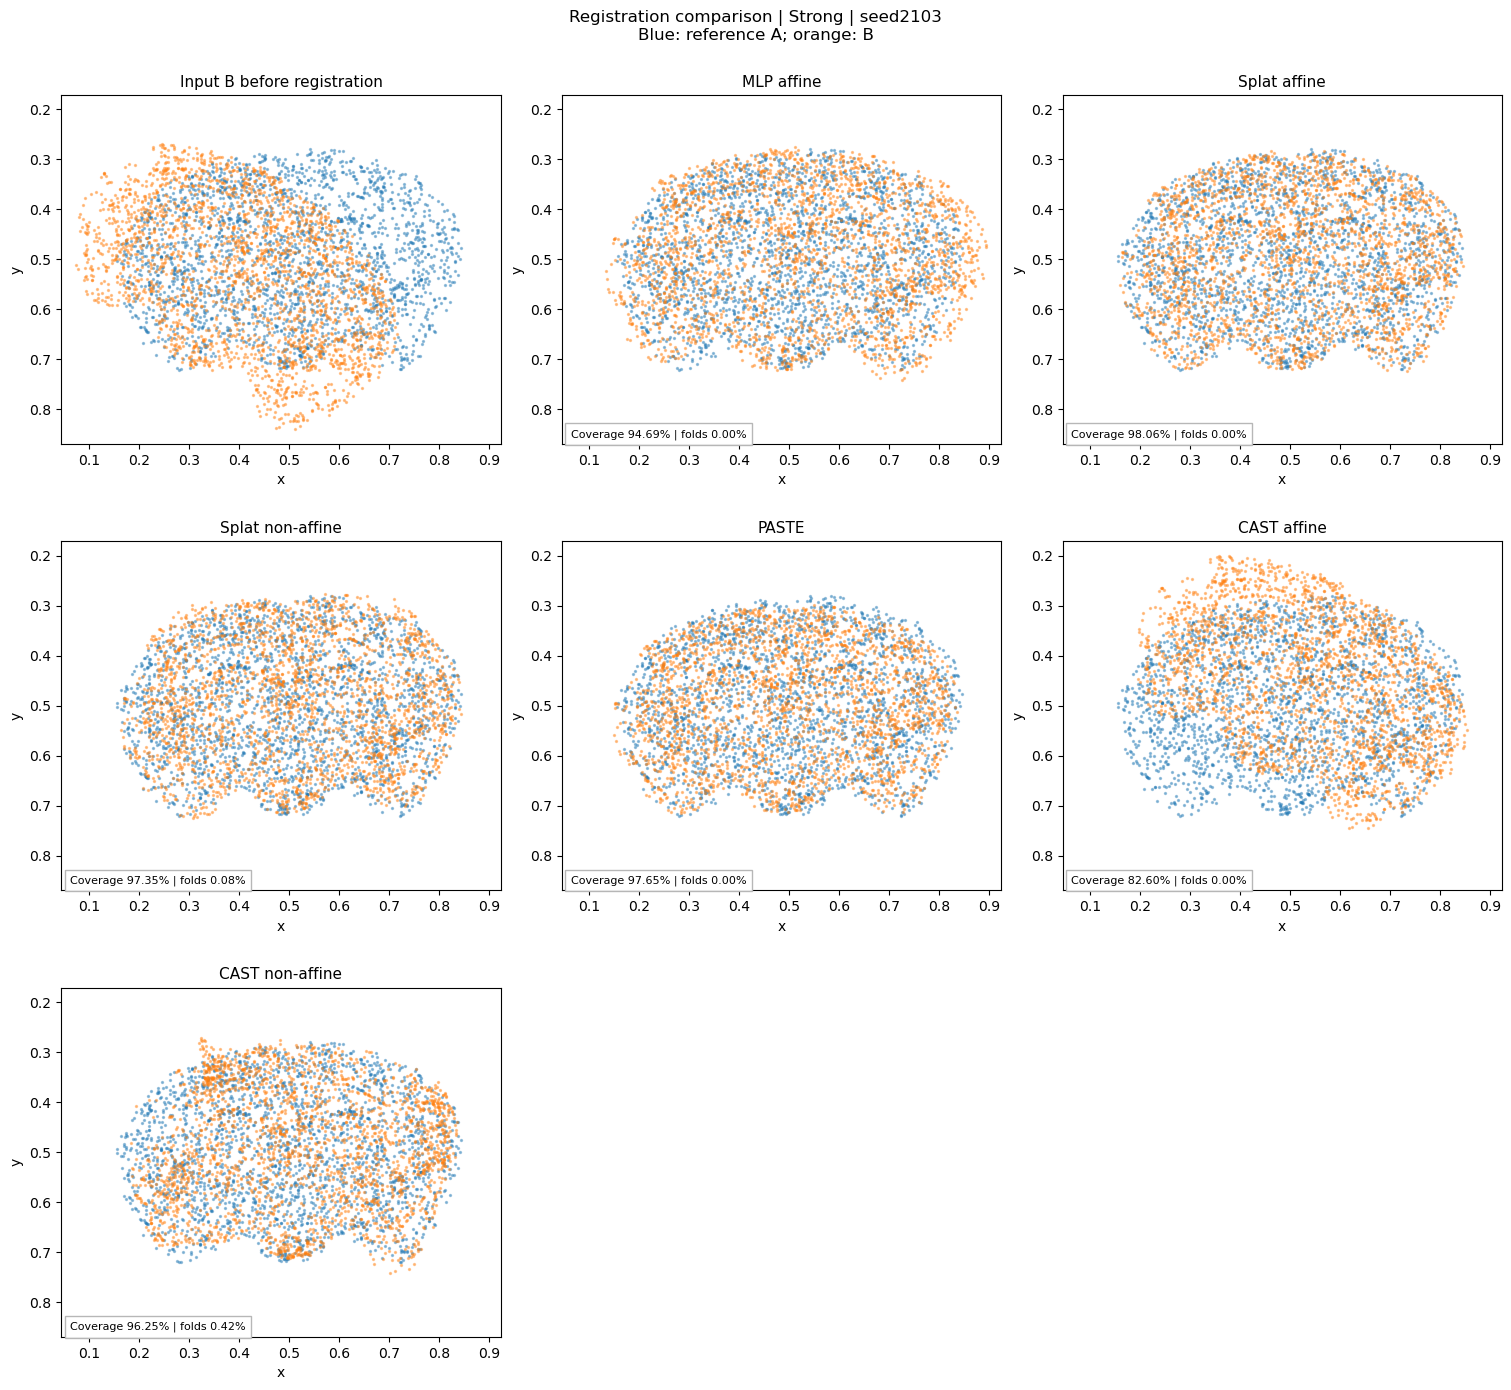

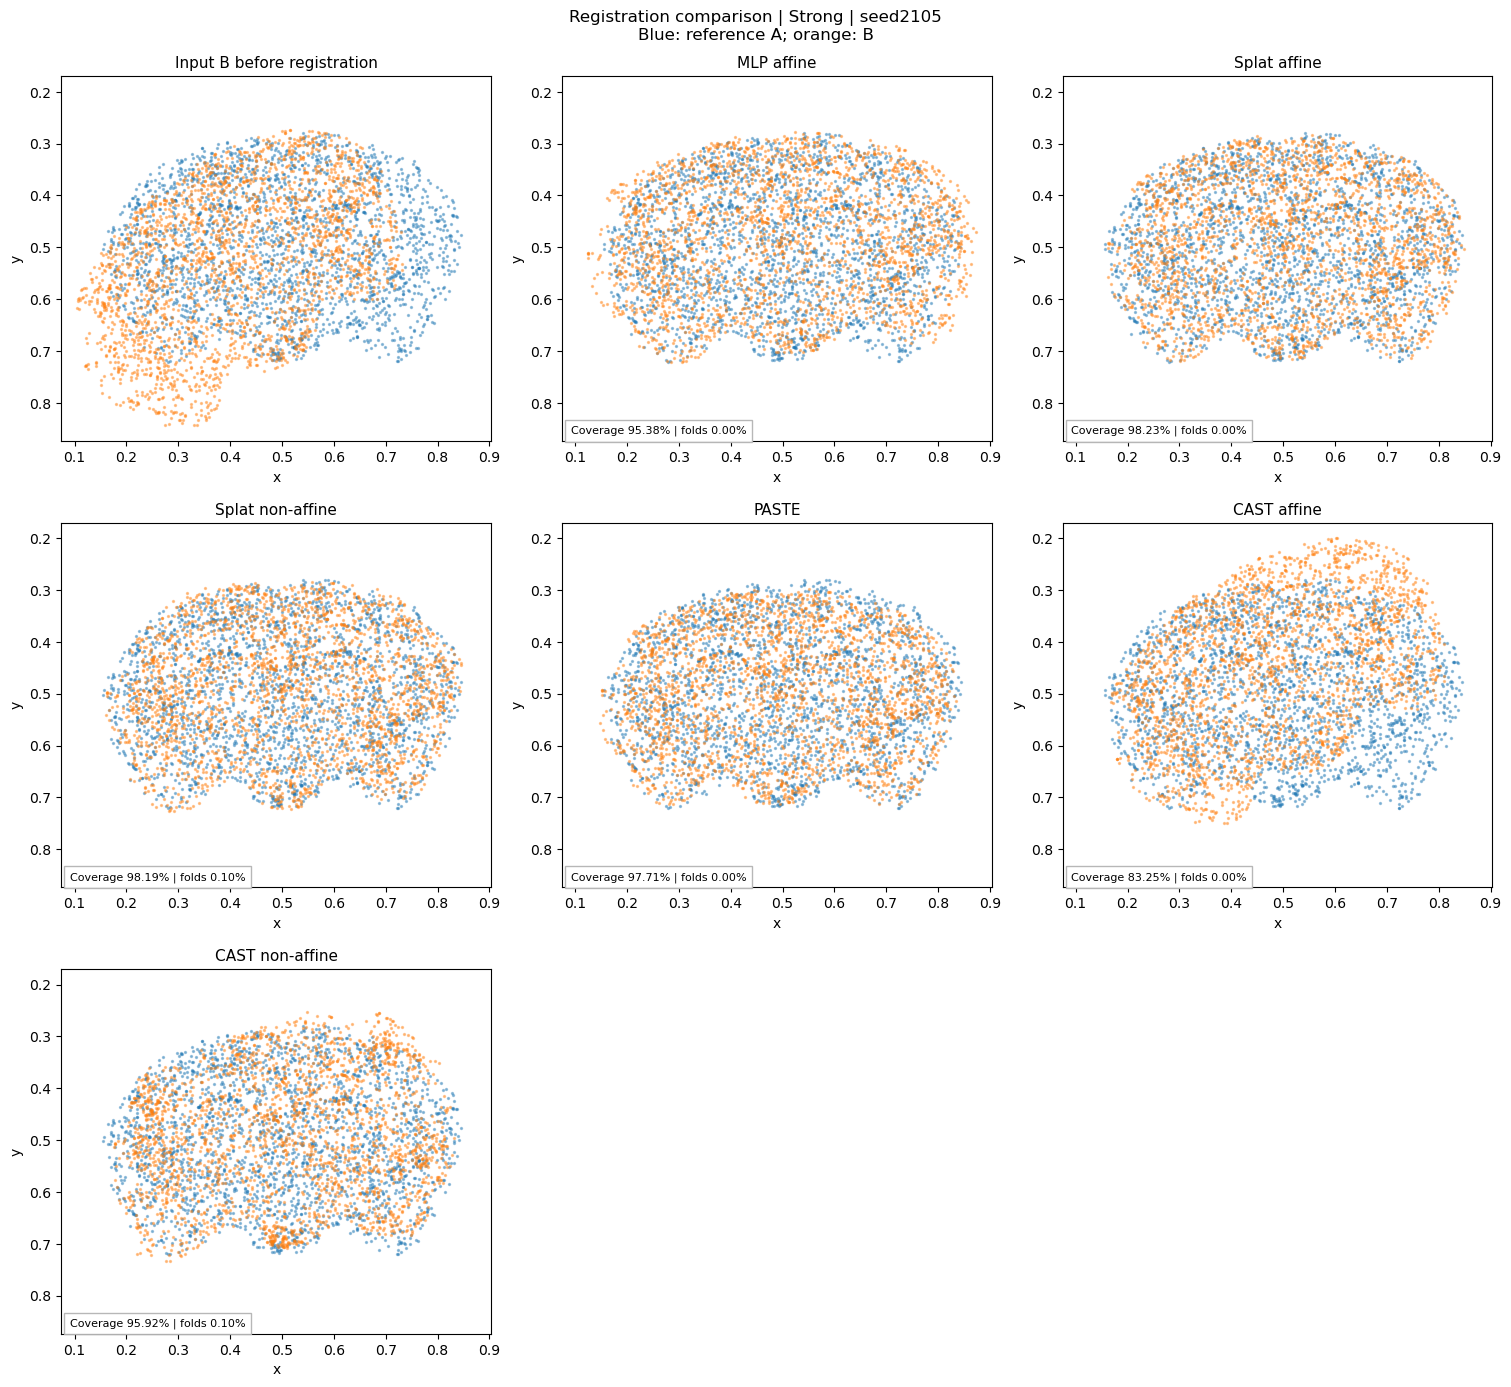

In [7]:
VIEW_CONDITION = 'level2_seed2105'
SHOW_ALL_CONDITIONS = True

settings = comparison.set_index('method')['candidate']
selections = [(method, int(settings[method])) for method in METHOD_ORDER if method != 'Unregistered']
for condition in (conditions if SHOW_ALL_CONDITIONS else [VIEW_CONDITION]):
    if condition not in conditions:
        raise ValueError(f'Unknown condition. Available: {conditions}')
    fig = overlay_figure(bundle['reference'], bundle['inputs'][condition], bundle['mappings'],
        bundle['metrics'], condition, selections, title=f'Registration comparison | {condition_labels[condition]}', show_folds=False)
    for ax, (method, _) in zip(fig.axes[1:], selections):
        ax.set_title(method)
    fig.savefig(FIGURE_DIR / f'alignment_{condition}.png', bbox_inches='tight', facecolor='white')
    plt.show()
    plt.close(fig)

## Interpretation

- Prefer improvements that retain coverage without introducing large distortions.
- A small expression-score difference is not evidence of better anatomical registration.
- Fold fractions describe a sampled triangulation, not an exact area of damaged tissue.
- Warning thresholds are the original 90% coverage and 1% folding/collapse checks;
  they do not exclude methods from this exploratory comparison.
- Settings were selected on these results. Performance on a new section pair remains
  the next validation step, not something this notebook has established.

The imposed perturbations are rigid rotation and translation. These test robustness to starting alignment, not recovery of a known non-affine deformation. Expression agreement is not anatomical ground truth.

The optional table below retains the original threshold-based selection for sensitivity
analysis. It does not change this notebook's settings or any frozen selections.

In [8]:
SHOW_THRESHOLD_SENSITIVITY = False
if SHOW_THRESHOLD_SENSITIVITY:
    display(threshold_sensitivity[['method', 'rule', 'candidate', 'mean_score', 'geometry_warnings']])